# DOE-022
## SMA / EMA / WMA ウィンドウ
- 対象銘柄: 9984
- 実験パラメータ
    - TYPE_MA_1
        - SMA, EMA, WMA
    - PERIOD_MA_1
        - 30, 60, 90
    - PERIOD_MA_2（長周期移動平均線）
        - 450, 900, 1350
- 固定パラメータ
    - LOSSCUT_SIMPLE（単純ロスカット）
        - -50
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-022"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "PERIOD_MA_2",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [pd.read_csv(file) for file in list_csv_file],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df_total)
print("\n *** Past", len(list_csv_file), "days statistics ***")
print("\n△ Profit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\n▼ Profit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\n△ Profit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\n▼ Profit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

   TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  Profit_Total  Profit_Median  Transactions_Median
0        EMA           30          450       -2826.0         -115.0                 46.0
1        EMA           30          900       -2349.0          -94.0                 32.0
2        EMA           30         1350       -2140.0          -81.0                 28.0
3        EMA           60          450       -2130.0          -94.0                 34.0
4        EMA           60          900       -1644.0          -82.0                 26.0
5        EMA           60         1350       -1326.0          -41.0                 20.0
6        EMA           90          450       -1563.0          -72.0                 30.0
7        EMA           90          900        -998.0          -45.0                 20.0
8        EMA           90         1350        -729.0          -24.0                 18.0
9        SMA           30          450       -2337.0         -120.0                 46.0
10       SMA         

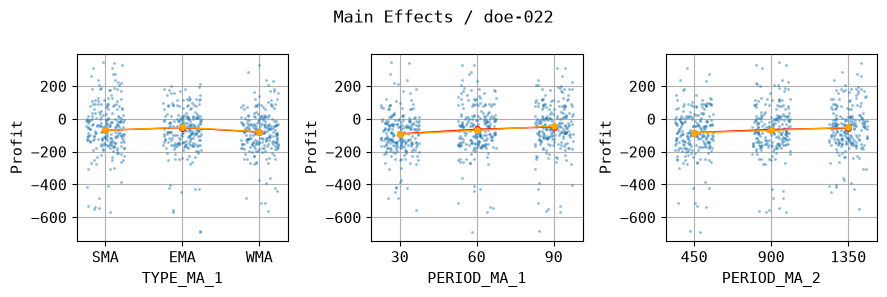

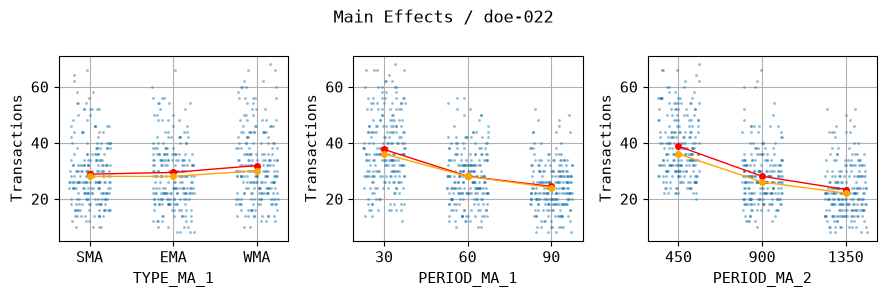

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 11

cols_param = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "PERIOD_MA_2",
]


for name_y in ["Profit", "Transactions"]:
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))

    for ax, col in zip(axes.flatten(), cols_param):
        sns.stripplot(
            data=df,
            x=col,
            y=name_y,
            ax=ax,
            size=2,
            jitter=0.25,  # 横方向へのばらつき具合
            alpha=0.5,  # 重なりが見やすいよう少し透明に
            color="tab:blue",  # 散布図の色を指定
        )

        # x の各水準ごとの平均値
        mean = df.groupby(col)[name_y].mean()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(mean)),
            mean.values,
            "o-",
            color="red",
            markersize=4,
            linewidth=1,
            zorder=5,  # 点の裏に隠れないよう前面に描画
        )

        # x の各水準ごとのメジアン
        median = df.groupby(col)[name_y].median()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(median)),
            median.values,
            "o-",
            color="orange",
            markersize=4,
            linewidth=1,
            zorder=5,
        )

        ax.set(xlabel=col, ylabel=name_y)
        ax.grid(True)

    fig.suptitle(f"Main Effects / {name_doe}", fontsize=12)

    plt.tight_layout()
    pngfile = f"../doe/{name_doe}/main_effect_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()